# Coursework Template

The baseline implementation follows the SAC algorithm as described in Haarnoja et al. (2018, 2019), using the hyperparameters recommended in the 2019 paper (Table 1). The network architecture (3-layer MLP, 256 units) and training hyperparameters (lr=3e-4, tau=0.005, gamma=0.99, batch_size=256, target_entropy=-|A|) are taken directly from that work. The replay buffer size of 300,000 follows common practice for BipedalWalker as seen in Stable Baselines3 configurations.

https://github.com/haarnoja/sac
https://github.com/DLR-RM/rl-baselines3-zoo (relay buffer size)

SAC paper:
Haarnoja et al. (2018) Soft Actor-Critic: Off-Policy Maximum Entropy Deep Reinforcement Learning with a Stochastic Actor. https://arxiv.org/abs/1801.01290
The follow-up: Haarnoja et al. 2019, https://arxiv.org/abs/1812.05905

## Setup

**Dependencies and imports**

This can take a minute...

In [2]:
%pip install swig
%pip install rldurham

  Obtaining dependency information for swig from https://files.pythonhosted.org/packages/a7/2f/7a6b14eea6d0247d3f803649f50df3cf3905714bd82f2c386fcfde9544f3/swig-4.4.1-py3-none-win_amd64.whl.metadata
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
    --------------------------------------- 0.1/2.5 MB 525.1 kB/s eta 0:00:05
    --------------------------------------- 0.1/2.5 MB 656.4 kB/s eta 0:00:04
   --- ------------------------------------ 0.2/2.5 MB 1.2 MB/s eta 0:00:03
   ---- ----------------------------------- 0.3/2.5 MB 1.5 MB/s eta 0:00:02
   ---- ----------------------------------- 0.3/2.5 MB 1.5 MB/s eta 0:00:02
   ------ --------------------------------- 0.4/2.5 MB 1.4 MB/s eta 0:00:02
   ------ --------------------------------- 0.4/2.5 MB 1.2 MB/s eta 0:00:02
   ---------- ----------------------------- 0.7/2.5 MB 1.8

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.0 requires FuzzyTM>=0.4.0, which is not installed.
tables 3.8.0 requires blosc2~=2.0.0, which is not installed.
tables 3.8.0 requires cython>=0.29.21, which is not installed.
numba 0.57.1 requires numpy<1.25,>=1.21, but you have numpy 1.26.4 which is incompatible.


## Heuristic demo

A small demo with a predefined heuristic that is suboptimal and has no notion of balance (designed for the orignal BipedalWalker environment, but should also work fine for rldurham/Walker).

In [ ]:
from gymnasium.envs.box2d.bipedal_walker import BipedalWalkerHeuristics

env = rld.make(
    "rldurham/Walker",
    # "BipedalWalker-v3",
    render_mode="human",
    # render_mode="rgb_array",
    hardcore=False,
    # hardcore=True,
)
_, obs, info = rld.seed_everything(42, env)

heuristics = BipedalWalkerHeuristics()

act = heuristics.step_heuristic(obs)
for _ in range(500):
    obs, rew, terminated, truncated, info = env.step(act)
    act = heuristics.step_heuristic(obs)
    if terminated or truncated:
        
        break
    if env.render_mode == "rgb_array":
        rld.render(env, clear=True)
env.close()

c:\Users\elixa\anaconda3\envs\myenv\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
Seed set to 42


## SAC Implementation

This is a Soft-Actor-Critic (SAC) implementation (adapted from https://github.com/seungeunrho/minimalRL/blob/master/sac.py) that does not perform very well, but is a decent starting point for the coursework. It can be outperformed by simpler methods (e.g. TD3) if they are well tuned and you are free to use any other method. Overall, the task is to make use of various ideas and principles that were covered in the lecture and/or that you find in papers to achieve the best possible performance.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""  # disable CUDA (better on Colab/NCC: choose an environment without GPU)
import torch
import rldurham as rld

In [2]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Normal
import numpy as np
import collections, random

In [3]:
class ReplayBuffer:
    def __init__(self, buffer_limit):
        self.buffer = collections.deque(maxlen=buffer_limit)

    def put(self, transition):
        self.buffer.append(transition)

    def sample(self, n):
        mini_batch = random.sample(self.buffer, n)
        s, a, r, s_p, d = zip(*mini_batch)
        return (
            torch.tensor(np.array(s),  dtype=torch.float),
            torch.tensor(np.array(a),  dtype=torch.float),
            torch.tensor(np.array(r),  dtype=torch.float).unsqueeze(1),
            torch.tensor(np.array(s_p),dtype=torch.float),
            torch.tensor(np.array(d),  dtype=torch.float).unsqueeze(1),
        )

    def size(self):
        return len(self.buffer)

In [6]:
# Replace ReplayBuffer class with StratifiedReplayBuffer to address reward sparsity issue (Wei & Ying, 2021):
class StratifiedReplayBuffer:
    def __init__(self, buffer_limit):
        # 5:1 failed:success ratio from Wei & Ying (2021)
        self.failed  = collections.deque(maxlen=int(buffer_limit * 0.83))
        self.success = collections.deque(maxlen=int(buffer_limit * 0.17))

    def put(self, transition, episode_failed):
        if episode_failed:
            self.failed.append(transition)
        else:
            self.success.append(transition)

    def sample(self, n):
        n_failed  = min(int(n * 5/6), len(self.failed))
        n_success = min(n - n_failed,  len(self.success))
        if n_success == 0 or len(self.success) == 0:
            batch = random.sample(list(self.failed), min(n, len(self.failed)))
        else:
            batch = (random.sample(list(self.failed),  n_failed) +
                     random.sample(list(self.success), n_success))
        s, a, r, s_p, d = zip(*batch)
        return (
            torch.tensor(np.array(s),   dtype=torch.float),
            torch.tensor(np.array(a),   dtype=torch.float),
            torch.tensor(np.array(r),   dtype=torch.float).unsqueeze(1),
            torch.tensor(np.array(s_p), dtype=torch.float),
            torch.tensor(np.array(d),   dtype=torch.float).unsqueeze(1),
        )

    def size(self):
        return len(self.failed) + len(self.success)

In [4]:
LOG_STD_MIN, LOG_STD_MAX = -5, 2

class PolicyNet(nn.Module):
    def __init__(self, obs_dim, act_dim, lr, init_alpha, lr_alpha, target_entropy):
        super().__init__()
        # Increased capacity (512 width) to handle Hardcore LIDAR mappings
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 512), nn.LayerNorm(512), nn.ReLU(),
            nn.Linear(512, 512),     nn.LayerNorm(512), nn.ReLU(),
            nn.Linear(512, 512),     nn.LayerNorm(512), nn.ReLU(),
        )
        self.fc_mu  = nn.Linear(512, act_dim)
        self.fc_log_std = nn.Linear(512, act_dim)

        self.optimizer = optim.Adam(self.parameters(), lr=lr)

        # Learnable temperature
        self.log_alpha = torch.tensor(np.log(init_alpha), requires_grad=True)
        self.log_alpha_optimizer = optim.Adam([self.log_alpha], lr=lr_alpha)
        self.target_entropy = target_entropy

    def forward(self, x):
        h = self.net(x)
        mu = self.fc_mu(h)
        log_std = self.fc_log_std(h).clamp(LOG_STD_MIN, LOG_STD_MAX)
        std = log_std.exp()

        dist = Normal(mu, std)
        u = dist.rsample()                                          # pre-squash sample
        action = torch.tanh(u)

        # Correct log-prob for tanh squashing
        log_prob = dist.log_prob(u) - torch.log(1 - action.pow(2) + 1e-6)
        log_prob = log_prob.sum(dim=-1, keepdim=True)

        return action, log_prob
        
    def train_net(self, q1, q2, mini_batch):
        s = mini_batch[0]
        a, log_prob = self.forward(s)

        q1_val = q1(s, a)
        q2_val = q2(s, a)
        min_q   = torch.min(q1_val, q2_val)

        # Policy loss: maximise Q - alpha * log_pi
        pi_loss = (self.log_alpha.exp().detach() * log_prob - min_q).mean()
        self.optimizer.zero_grad()
        pi_loss.backward()
        nn.utils.clip_grad_norm_(self.parameters(), 1.0)
        self.optimizer.step()

        # Alpha (temperature) loss
        alpha_loss = -(self.log_alpha.exp() * (log_prob + self.target_entropy).detach()).mean()
        self.log_alpha_optimizer.zero_grad()
        alpha_loss.backward()
        self.log_alpha_optimizer.step()

    @property
    def alpha(self):
        return self.log_alpha.exp().item() 

In [5]:
class QNet(nn.Module):
    def __init__(self, obs_dim, act_dim, lr):
        super().__init__()
        # Increased capacity (512 width) for complex value estimation
        self.net = nn.Sequential(
            nn.Linear(obs_dim + act_dim, 512), nn.LayerNorm(512), nn.ReLU(),
            nn.Linear(512, 512),               nn.LayerNorm(512), nn.ReLU(),
            nn.Linear(512, 512),               nn.LayerNorm(512), nn.ReLU(),
            nn.Linear(512, 1),
        )
        self.optimizer = optim.Adam(self.parameters(), lr=lr)

    def forward(self, s, a):
        x = torch.cat([s, a], dim=-1)
        return self.net(x)

    def train_net(self, td_target, mini_batch):
        s, a = mini_batch[0], mini_batch[1]
        loss = F.mse_loss(self.forward(s, a), td_target.detach())
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.parameters(), 1.0)
        self.optimizer.step()

    def soft_update(self, net_target, tau):
        for p_tgt, p in zip(net_target.parameters(), self.parameters()):
            p_tgt.data.copy_(p_tgt.data * (1.0 - tau) + p.data * tau)

In [7]:
class Agent(nn.Module):
    def __init__(
        self,
        env,
        lr_pi=3e-4,
        lr_q=3e-4,
        lr_alpha=3e-4,
        init_alpha=0.2,
        buffer_limit=1_000_000,
        gamma=0.99,
        batch_size=128,
        tau=0.005,
        grad_steps_per_episode=200,
        policy_delay=2,
        warmup_steps=5_000,
        num_critics=5,   # ensemble size
    ):
        super().__init__()

        self.env = env
        self.gamma = gamma
        self.batch_size = batch_size
        self.tau = tau
        self.grad_steps_per_episode = grad_steps_per_episode
        self.warmup_steps = warmup_steps
        self.total_steps = 0
        self.policy_delay = policy_delay
        self.update_step = 0
        self.num_critics = num_critics

        discrete_act, discrete_obs, act_dim, obs_dim = rld.env_info(env, print_out=True)

        target_entropy = -1.0

        self.memory = StratifiedReplayBuffer(buffer_limit)

        # Critic Ensemble
        self.critics = nn.ModuleList(
            [QNet(obs_dim, act_dim, lr_q) for _ in range(self.num_critics)]
        )

        self.critic_targets = nn.ModuleList(
            [QNet(obs_dim, act_dim, lr_q) for _ in range(self.num_critics)]
        )

        # copy weights to targets
        for i in range(self.num_critics):
            self.critic_targets[i].load_state_dict(self.critics[i].state_dict())

        # Policy 
        self.pi = PolicyNet(obs_dim, act_dim, lr_pi, init_alpha, lr_alpha, target_entropy)

    def action(self, s, deterministic=False):
        with torch.no_grad():
            s_t = torch.from_numpy(s).float().unsqueeze(0)

            if deterministic:
                h = self.pi.net(s_t)
                a = torch.tanh(self.pi.fc_mu(h))
            else:
                a, _ = self.pi(s_t)

            return a.squeeze(0).numpy()

    def put(self, s, a, r, s_prime, done):
        self.memory.put((s, a, r, s_prime, done))

    def train(self):

        if self.memory.size() < max(self.batch_size, self.warmup_steps):
            return

        for _ in range(self.grad_steps_per_episode):

            mb = self.memory.sample(self.batch_size)

            td_target = self._calc_target(mb)

            # Train all critics with the same target
            for critic in self.critics:
                critic.train_net(td_target, mb)

            # Delayed actor update 
            if self.update_step % self.policy_delay == 0:

                # pass two critics for compatibility with existing PolicyNet
                self.pi.train_net(self.critics[0], self.critics[1], mb)

            # Target updates 
            for critic, critic_target in zip(self.critics, self.critic_targets):
                critic.soft_update(critic_target, self.tau)

            self.update_step += 1

    def _calc_target(self, mini_batch):

        s, a, r, s_prime, done_mask = mini_batch

        with torch.no_grad():

            a_prime, log_prob = self.pi(s_prime)

            # target policy smoothing
            noise = (torch.randn_like(a_prime) * 0.1).clamp(-0.25, 0.25)
            a_prime = (a_prime + noise).clamp(-1, 1)

            # compute Q from every target critic
            q_targets = []

            for critic_target in self.critic_targets:
                q_targets.append(critic_target(s_prime, a_prime))

            q_targets = torch.stack(q_targets)

            # pessimistic estimate
            min_q_next = torch.min(q_targets, dim=0)[0]

            target = r + self.gamma * done_mask * (
                min_q_next - self.pi.log_alpha.exp() * log_prob
            )

        return target

    def episode(self):
        done = False
        s, _ = self.env.reset()
        info = {}
        episode_failed = True    # assume fall until max steps reached

        while not done:
            if self.total_steps < self.warmup_steps:
                a = self.env.action_space.sample()
            else:
                a = self.action(s)

            s_prime, r, terminated, truncated, info = self.env.step(a)
            done = terminated or truncated

            if truncated:            # survived max steps = success
                episode_failed = False

            if r <= -100:
                scaled_r = -5.0
            else:
                scaled_r = r * 5.0

            # pass episode_failed flag to buffer
            self.memory.put((s, a, scaled_r, s_prime, 0.0 if done else 1.0),
                            episode_failed)
            s = s_prime
            self.total_steps += 1
        return info

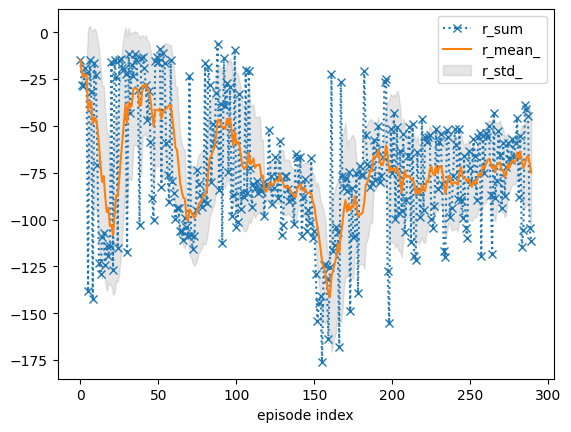

In [ ]:
# Environment setup
env = rld.make("rldurham/Walker", render_mode="rgb_array", hardcore=True)
rld.seed_everything(42, env)

# Clip large negative rewards (standard trick for Walker)
env = rld.transparent_wrapper(gym.wrappers.ClipReward)(env, min_reward=-10)

env = rld.Recorder(
    env,
    smoothing=10,
    video=True,
    video_folder="videos-hardcore",
    video_prefix="zzjw57-agent-video-hardcore",  
    logs=True,
)

recorder = env
recorder.video = False
tracker = rld.InfoTracker()




# Training loop
agent = Agent(env)
max_episodes = 2000

for n_epi in range(max_episodes):
    # Record a video every 100 episodes 
    recorder.video = (n_epi + 1) % 100 == 0

    info = agent.episode()
    env.add_stats(info, ignore_existing=True)
    tracker.track(info)
    agent.train()

    if (n_epi + 1) % 10 == 0:
        print(f"Episode {n_epi+1} | alpha={agent.pi.alpha:.4f} | buffer={agent.memory.size()}")
        tracker.plot(r_mean_=True, r_std_=True, r_sum=dict(linestyle=':', marker='x'))

env.close()
env.write_log(folder="logs-hardcore", file="zzjw57-agent-log-hardcore.txt") 

## TD3 (Twin Delayed Deep Deterministic Policy Gradient) for rldurham/Walker
Algorithm source:
  Fujimoto et al. (2018) "Addressing Function Approximation Error in Actor-Critic Methods"
  https://arxiv.org/abs/1802.09477

Official author implementation (reference for architecture & hyperparameters):
  https://github.com/sfujim/TD3

Stable Baselines3 TD3 defaults (cross-reference for hyperparameters):
  https://stable-baselines3.readthedocs.io/en/master/modules/td3.html

How TD3 differs from DDPG and why it matters for Walker:
  - Two critic networks (twin) → takes the minimum to reduce Q-value overestimation
  - Delayed policy updates → actor only updated every d steps, giving critics time to stabilise
  - Target policy smoothing → adds noise to target actions, preventing the actor from
    exploiting narrow Q-value spikes (critical for the bumpy Walker terrain)

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""  # CPU only — Walker is I/O bound, not compute bound

import torch
import rldurham as rld
import gymnasium as gym
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import collections, random

In [2]:
# Replay Buffer
# Source: standard experience replay (Mnih et al. 2015, https://arxiv.org/abs/1312.5602)

class ReplayBuffer:
    def __init__(self, buffer_limit):
        self.buffer = collections.deque(maxlen=buffer_limit)

    def put(self, transition):
        self.buffer.append(transition)

    def sample(self, n):
        mini_batch = random.sample(self.buffer, n)
        s, a, r, s_p, d = zip(*mini_batch)
        return (
            torch.tensor(np.array(s),   dtype=torch.float),
            torch.tensor(np.array(a),   dtype=torch.float),
            torch.tensor(np.array(r),   dtype=torch.float).unsqueeze(1),
            torch.tensor(np.array(s_p), dtype=torch.float),
            torch.tensor(np.array(d),   dtype=torch.float).unsqueeze(1),
        )

    def size(self):
        return len(self.buffer)

In [3]:
# Actor Network  (deterministic policy)
# TD3 uses a deterministic actor unlike SAC's stochastic actor.
# Architecture: 3-layer MLP, 256 units — matches Table 1 of Fujimoto et al. (2018).
# tanh output squashes actions to [-1, 1] to match Walker's action space bounds.

class Actor(nn.Module):
    def __init__(self, obs_dim, act_dim, lr=3e-4):
        super().__init__()
        # Add LayerNorm for better training stability (common in continuous control)
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 256), nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),     nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),     nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, act_dim), nn.Tanh(),
        )
        self.optimizer = optim.Adam(self.parameters(), lr=lr)

    def forward(self, s):
        return self.net(s)

In [4]:
# Critic Network  (Q-function, scalar output)
# TD3 maintains two independent critics to combat overestimation bias.
# Each critic takes (state, action) concatenated as input → outputs scalar Q-value.
# Source: Section 4 "Clipped Double Q-Learning" in Fujimoto et al. (2018).

class Critic(nn.Module):
    def __init__(self, obs_dim, act_dim, lr=3e-4):
        super().__init__()
        # Q1
        self.q1 = nn.Sequential(
            nn.Linear(obs_dim + act_dim, 256), nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),               nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),               nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 1),
        )
        # Q2 — independent weights, same architecture
        self.q2 = nn.Sequential(
            nn.Linear(obs_dim + act_dim, 256), nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),               nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 256),               nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 1),
        )
        # Single optimiser over both critics — standard practice, see SB3 TD3 source:
        # https://github.com/DLR-RM/stable-baselines3/blob/master/stable_baselines3/td3/td3.py
        self.optimizer = optim.Adam(self.parameters(), lr=lr)

    def forward(self, s, a):
        """Returns both Q-values (used during critic training)."""
        x = torch.cat([s, a], dim=-1)
        return self.q1(x), self.q2(x)

    def q1_only(self, s, a):
        """Returns only Q1 (used during actor update — only need one critic)."""
        x = torch.cat([s, a], dim=-1)
        return self.q1(x)

    def soft_update(self, target, tau):
        # Polyak averaging: θ_target ← τ·θ + (1-τ)·θ_target
        # Source: Lillicrap et al. DDPG (2016) https://arxiv.org/abs/1509.02971
        for p_tgt, p in zip(target.parameters(), self.parameters()):
            p_tgt.data.copy_(p_tgt.data * (1.0 - tau) + p.data * tau)

In [7]:
# TD3 Agent

class Agent(nn.Module):
    def __init__(
        self,
        env,
        lr_actor=3e-4,           # learning rate for actor; Fujimoto et al. Table 1
        lr_critic=3e-4,          # learning rate for critic; Fujimoto et al. Table 1
        gamma=0.99,              # discount factor; Fujimoto et al. Table 1
        tau=0.005,               # soft update rate; Fujimoto et al. Table 1
        buffer_limit=500_000,    # large buffer keeps diverse experiences; see SB3 defaults
        batch_size=256,          # Fujimoto et al. Table 1
        policy_noise=0.2,        # std of smoothing noise added to target actions
                                 # "Target Policy Smoothing" — Fujimoto et al. Section 5.3
        noise_clip=0.5,          # clips smoothing noise to [-noise_clip, noise_clip]
                                 # prevents target actions moving far outside valid range
        policy_delay=2,          # actor updated every d=2 critic steps
                                 # "Delayed Policy Updates" — Fujimoto et al. Section 5.2
        expl_noise=0.2,          # Gaussian exploration noise std added to actions
                                 # Fujimoto et al. Section 6; SB3 default is also 0.1
        warmup_steps=15_000,     # random exploration before any training begins
        grad_steps_per_episode=200, # number of gradient updates to run after each episode 
    ):
        super().__init__()
        self.env = env
        self.gamma = gamma
        self.tau = tau
        self.batch_size = batch_size
        self.policy_noise = policy_noise
        self.noise_clip = noise_clip
        self.policy_delay = policy_delay
        self.initial_noise = expl_noise
        self.final_noise = 0.005  # minimum exploration noise for late training stages
        self.noise_decay_steps = 1_000_000
        self.warmup_steps = warmup_steps
        self.grad_steps_per_episode = grad_steps_per_episode

        self.total_steps = 0   # tracks environment interactions
        self.update_count = 0  # tracks gradient update steps (for delayed actor update)

        discrete_act, discrete_obs, self.act_dim, obs_dim = rld.env_info(env, print_out=True)

        self.memory = ReplayBuffer(buffer_limit)

        # Actor and its target (target used only for TD backup, not for action selection)
        self.actor        = Actor(obs_dim, self.act_dim, lr_actor)
        self.actor_target = Actor(obs_dim, self.act_dim, lr_actor)
        self.actor_target.load_state_dict(self.actor.state_dict())

        # Twin critic and its target
        self.critic        = Critic(obs_dim, self.act_dim, lr_critic)
        self.critic_target = Critic(obs_dim, self.act_dim, lr_critic)
        self.critic_target.load_state_dict(self.critic.state_dict())

    # Action selection 
    def action(self, s, add_noise=True):
        with torch.no_grad():
            s_t = torch.from_numpy(s).float().unsqueeze(0)
            a = self.actor(s_t).squeeze(0).numpy()

        if add_noise:
            # Add Gaussian exploration noise and clip to valid action range [-1, 1]
            # This is different from the target smoothing noise — it exists purely
            # for exploration during data collection.
            # Source: Fujimoto et al. (2018) Section 6, Equation for exploration policy
            # Implement linear decay of exploration noise over time (common practice)
            noise_scale = self.final_noise + (
                self.initial_noise - self.final_noise
            ) * max(0, (self.noise_decay_steps - self.total_steps)) / self.noise_decay_steps

            noise = np.random.normal(0, noise_scale, size=self.act_dim)
            a = np.clip(a + noise, -1.0, 1.0)

        return a

    def put(self, s, a, r, s_prime, done):
        self.memory.put((s, a, r, s_prime, done))

    # Gradient update step 
    def _update(self):
        mb = self.memory.sample(self.batch_size)
        s, a, r, s_prime, done_mask = mb

        # Critic update
        with torch.no_grad():
            # Target Policy Smoothing: add clipped noise to next action
            # Prevents the actor from exploiting narrow peaks in the Q-function.
            # Source: Fujimoto et al. (2018) Section 5.3, Algorithm 1 lines 9-10
            noise = torch.clamp(
                torch.randn_like(a) * self.policy_noise,
                -self.noise_clip,
                self.noise_clip
            )
            # Next action from target actor (smoothed)
            a_prime = torch.clamp(self.actor_target(s_prime) + noise, -1.0, 1.0)

            # Clipped Double Q: take min of both target critics to form TD target
            # Reduces overestimation bias vs single critic or naive double Q.
            # Source: Fujimoto et al. (2018) Section 4, Equation 5
            q1_next, q2_next = self.critic_target(s_prime, a_prime)
            q_next = torch.min(q1_next, q2_next)
            td_target = r + self.gamma * done_mask * q_next  # done_mask=0 at terminal

        # Compute loss for both critics simultaneously
        q1_val, q2_val = self.critic(s, a)
        critic_loss = F.mse_loss(q1_val, td_target) + F.mse_loss(q2_val, td_target)

        self.critic.optimizer.zero_grad()
        critic_loss.backward()
        nn.utils.clip_grad_norm_(self.critic.parameters(), 1.0)  # prevents exploding gradients
        self.critic.optimizer.step()

        # Delayed Actor update 
        # Actor is updated less frequently than the critic, giving Q-values time
        # to stabilise before the policy is improved against them.
        # Source: Fujimoto et al. (2018) Section 5.2, "Delayed Policy Updates"
        if self.update_count % self.policy_delay == 0:
            # Actor loss: maximise Q1 (only need one critic for policy gradient)
            actor_loss = -self.critic.q1_only(s, self.actor(s)).mean()

            self.actor.optimizer.zero_grad()
            actor_loss.backward()
            nn.utils.clip_grad_norm_(self.actor.parameters(), 1.0)
            self.actor.optimizer.step()

            # Soft update both target networks (only when actor is updated)
            # Source: Fujimoto et al. (2018) Algorithm 1 lines 14-15
            self.critic.soft_update(self.critic_target, self.tau)
            for p, p_tgt in zip(self.actor.parameters(), self.actor_target.parameters()):
                p_tgt.data.copy_(self.tau * p.data + (1 - self.tau) * p_tgt.data)

        self.update_count += 1

    def train(self):
        """Run gradient_steps_per_episode update steps after each episode."""
        if self.memory.size() < max(self.batch_size, self.warmup_steps):
            return
        for _ in range(self.grad_steps_per_episode):
            self._update()

    # Episode rollout 
    def episode(self):
        done = False
        s, _ = self.env.reset()
        info = {}
        while not done:
            # Random actions during warmup for diverse initial buffer coverage
            if self.total_steps < self.warmup_steps:
                a = self.env.action_space.sample()
            else:
                a = self.action(s, add_noise=True)

            s_prime, r, terminated, truncated, info = self.env.step(a)
            done = terminated or truncated

            # Bootstrap through time-limit truncation; only stop bootstrapping on true termination
            not_done = 0.0 if terminated else 1.0

            # Reward scaling
            scaled_r = r * 0.5 if r <= -10 else r * 3.0
            self.put(s, a, scaled_r, s_prime, not_done)

            s = s_prime
            self.total_steps += 1
        return info


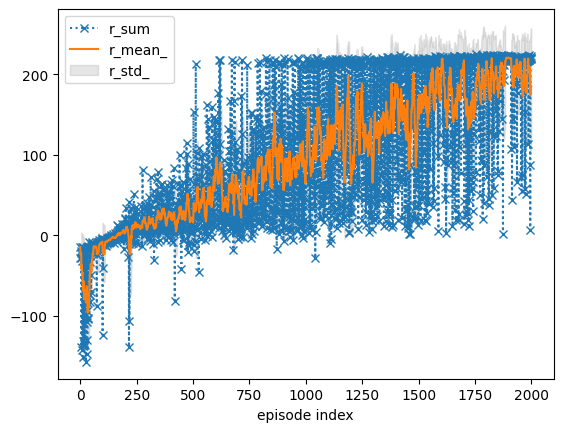

In [8]:
env = rld.make("rldurham/Walker", render_mode="rgb_array", hardcore=True)
rld.seed_everything(42, env)

# reward clipping 
env = rld.transparent_wrapper(gym.wrappers.ClipReward)(env, min_reward=-10)

env = rld.Recorder(
    env,
    smoothing=10,
    video=True,
    video_folder="videos-hardcore",
    video_prefix="zzjw57-agent-video-hardcore",   
    logs=True,
)

recorder = env
recorder.video = False
tracker = rld.InfoTracker()

# Training loop 
agent = Agent(env)
max_episodes = 2000

for n_epi in range(max_episodes):
    recorder.video = (n_epi + 1) % 100 == 0  # record every 100 episodes

    info = agent.episode()
    env.add_stats(info, ignore_existing=True)
    tracker.track(info)
    agent.train()

    if n_epi == 1500:
        for param_group in agent.actor.optimizer.param_groups:
            param_group['lr'] = 1e-4
        for param_group in agent.critic.optimizer.param_groups:
            param_group['lr'] = 1e-4

    if n_epi == 1800:
        for param_group in agent.actor.optimizer.param_groups:
            param_group['lr'] = 3e-5
        for param_group in agent.critic.optimizer.param_groups:
            param_group['lr'] = 3e-5

    if n_epi == 1900:
        for param_group in agent.actor.optimizer.param_groups:
            param_group['lr'] = 1e-5
        for param_group in agent.critic.optimizer.param_groups:
            param_group['lr'] = 1e-5

    if (n_epi + 1) % 10 == 0:
        print(f"Episode {n_epi+1} | steps={agent.total_steps} | updates={agent.update_count}")
        tracker.plot(r_mean_=True, r_std_=True, r_sum=dict(linestyle=':', marker='x'))

env.close()
env.write_log(folder="logs-hardcore", file="zzjw57-agent-log-hardcore.txt") 